In [1]:
import pandas as pd
import pickle
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt
import shap
import numpy as np
import pandas as pd
import os


In [2]:

datafile = "Dataset_14_features.xlsx"

df = pd.read_excel(datafile)

with open('14_feat_NGB_model.pkl', 'rb') as file:
    NGB_model = pickle.load(file)

X = df.drop(['Formulation_number', 'Modification','Drug', 'Cross_linker', 'DL'], axis='columns')
y = df['DL']

In [3]:
stdScale = StandardScaler().fit(X)
X_scale = stdScale.transform(X)

In [4]:
NGB_model

NGBRegressor(Base=DecisionTreeRegressor(max_depth=16), col_sample=0.8,
             learning_rate=0.1, minibatch_frac=0.8, n_estimators=100,
             random_state=RandomState(MT19937) at 0x22DE3FFFA40)

In [5]:
bestModel = NGB_model
bestModel.fit(X, y)
explainer = shap.TreeExplainer(NGB_model)
shap_values = explainer(X)

[iter 0] loss=4.3042 val_loss=0.0000 scale=2.0000 norm=29.3670


c:\Users\Afra\AppData\Local\Programs\Python\Python39\lib\site-packages\shap\explainers\_tree.py:1403: UserWarning: Translating model_output="raw" to model_output=0 for the 0-th parameter in the distribution. Use model_output=0 directly to avoid this warning.
  warnings.warn(


In [6]:
shap_values

.values =
array([[  0.31397412,  -6.96977745,   0.49772437, ...,  -2.94006534,
         -1.38393847,  -2.26077767],
       [  0.27683533,  -6.65241889,   0.55763347, ...,  -1.51845154,
         -1.19075375,  -1.91981559],
       [ -0.29586715,  -6.68364156,   0.30859805, ...,   1.57400798,
         -2.74502685,  -2.35353202],
       ...,
       [ -1.55962745,  -1.66187212,   0.16263621, ...,   4.41059653,
          0.43056293,   2.05323267],
       [  1.65946106,   0.93655385,   0.38162227, ...,   4.8537605 ,
          0.89628164,  -1.92515436],
       [  0.28157988, -12.09523502,   0.25271077, ...,   1.13811046,
         -0.49376607,  -2.36748106]])

.base_values =
array([24.70671799, 24.70671799, 24.70671799, 24.70671799, 24.70671799,
       24.70671799, 24.70671799, 24.70671799, 24.70671799, 24.70671799,
       24.70671799, 24.70671799, 24.70671799, 24.70671799, 24.70671799,
       24.70671799, 24.70671799, 24.70671799, 24.70671799, 24.70671799,
       24.70671799, 24.70671799, 24.7

In [7]:
shap_values.values

array([[  0.31397412,  -6.96977745,   0.49772437, ...,  -2.94006534,
         -1.38393847,  -2.26077767],
       [  0.27683533,  -6.65241889,   0.55763347, ...,  -1.51845154,
         -1.19075375,  -1.91981559],
       [ -0.29586715,  -6.68364156,   0.30859805, ...,   1.57400798,
         -2.74502685,  -2.35353202],
       ...,
       [ -1.55962745,  -1.66187212,   0.16263621, ...,   4.41059653,
          0.43056293,   2.05323267],
       [  1.65946106,   0.93655385,   0.38162227, ...,   4.8537605 ,
          0.89628164,  -1.92515436],
       [  0.28157988, -12.09523502,   0.25271077, ...,   1.13811046,
         -0.49376607,  -2.36748106]])

In [8]:
MOD_chitosan = df.loc[df['Modification'] == 'Thiolated chitosan']
MOD_chitosan

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
128,30,Thiolated chitosan,Tobramycin,TPP,1.00,2.00,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,189.0,43.43,10,-6.2958
129,30,Thiolated chitosan,Tobramycin,TPP,0.50,1.49,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,156.0,48.76,10,-6.2958
130,30,Thiolated chitosan,Tobramycin,TPP,0.33,1.33,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,143.0,55.34,10,-6.2958
131,30,Thiolated chitosan,Tobramycin,TPP,0.25,1.25,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,139.0,45.56,10,-6.2958
132,30,Thiolated chitosan,Tobramycin,TPP,0.20,1.20,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,134.0,58.76,10,-6.2958
133,30,Thiolated chitosan,Tobramycin,TPP,0.17,1.16,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,112.0,63.19,10,-6.2958
134,30,Thiolated chitosan,Tobramycin,TPP,0.14,1.14,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,106.0,61.67,10,-6.2958
135,30,Thiolated chitosan,Tobramycin,TPP,0.13,1.12,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,73.0,87.45,10,-6.2958
136,30,Thiolated chitosan,Tobramycin,TPP,0.11,1.11,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,137.0,82.45,10,-6.2958
137,31,Thiolated chitosan,5-Fluorouracil,TPP,0.44,0.22,1,2,60.0,0.09,4.20,367.86,0.89,130.08,7.18,150.0,16.55,2,-0.7977


In [9]:
MOD_chitosan.loc[[128]]

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
128,30,Thiolated chitosan,Tobramycin,TPP,1.0,2.0,1,2,11.0,0.43,4.34,367.86,0.89,467.51,12.54,189.0,43.43,10,-6.2958


In [10]:
shap_values.values[128]

array([-4.00605771e+00,  9.73438870e+00,  1.82186444e-01,  8.83950986e-01,
       -1.78974476e-02,  1.44950340e+00,  6.82435743e+00, -2.29563337e-01,
       -2.40474181e-03,  2.17384347e+00, -8.94394596e-01, -5.65465192e-01,
        1.03714250e+00,  2.15369210e+00])

<Figure size 1800x400 with 0 Axes>

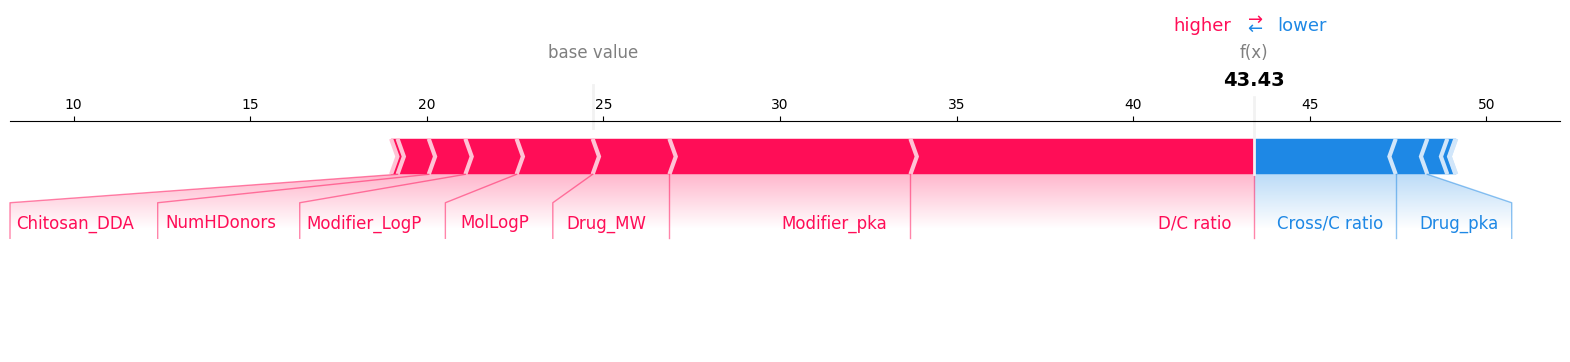

In [11]:
os.makedirs("ArticleFigures", exist_ok=True)

plt.figure(figsize=(18, 4))

shap.plots.force(
    explainer.expected_value,
    shap_values.values[128],
    feature_names=X.columns.tolist(),
    link="identity",
    plot_cmap="RdBu",
    matplotlib=True,
    show=False,
    ordering_keys=None,
    ordering_keys_time_format=None,
    text_rotation=0,
    contribution_threshold=0.05
)

fig = plt.gcf()

fig.savefig(
    "ArticleFigures/Figure_7A.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/Figure_7A.jpg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/Figure_7A.jpeg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/Figure_7A.tiff",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/Figure_7A.pdf",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

plt.show()
plt.close(fig)

In [13]:
MOD_Trimethyl_Chitosan = df.loc[df['Modification'] == 'Chitosan']
MOD_Trimethyl_Chitosan

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
0,1,Chitosan,Doxorubicin hydrochloride,TPP,0.07,0.33,1,3,0.0,0.0,0.0,367.86,0.89,580.00,8.01,489.30,12.40,6,0.42310
1,1,Chitosan,Doxorubicin hydrochloride,TPP,0.10,0.33,1,3,0.0,0.0,0.0,367.86,0.89,580.00,8.01,342.20,15.30,6,0.42310
2,1,Chitosan,Doxorubicin hydrochloride,TPP,0.17,0.33,1,3,0.0,0.0,0.0,367.86,0.89,580.00,8.01,209.60,14.90,6,0.42310
3,2,Chitosan,Vancomycin,Sodium carboxymethylcellulose,0.25,10.00,1,2,0.0,0.0,0.0,250000.00,4.50,1449.25,2.99,194.70,52.00,19,0.10620
4,2,Chitosan,Vancomycin,Sodium alginate,0.25,10.00,1,2,0.0,0.0,0.0,140000.00,3.60,1449.25,2.99,350.10,51.80,19,0.10620
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,19,Chitosan,oxaliplatin,TPP,0.27,0.25,1,2,0.0,0.0,0.0,367.86,0.89,397.29,1.36,188.40,12.40,2,1.55510
86,20,Chitosan,Levofloxacin,TPP,0.40,1.00,1,2,0.0,0.0,0.0,367.86,0.89,361.40,5.35,161.90,4.23,1,1.54400
87,20,Chitosan,Levofloxacin,TPP,0.40,0.67,1,2,0.0,0.0,0.0,367.86,0.89,361.40,5.35,176.97,4.02,1,1.54400
88,20,Chitosan,Levofloxacin,TPP,0.40,0.50,1,2,0.0,0.0,0.0,367.86,0.89,361.40,5.35,283.97,3.13,1,1.54400


In [14]:
MOD_Trimethyl_Chitosan.loc[[36]]

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
36,12,Chitosan,5-fluorouracil,TPP,0.2,0.25,1,3,0.0,0.0,0.0,367.86,0.89,130.08,7.18,283.9,7.26,2,-0.7977


In [15]:
shap_values.values[36]

array([-7.25634774e-01, -6.53133888e+00,  4.24095812e-01,  6.25510839e-01,
        1.31454421e-01, -1.08495826e+00, -6.73770702e-01,  4.78920754e-03,
        6.00398927e-02, -3.80441469e+00,  4.57652219e-01, -4.20642847e+00,
       -1.04582530e+00, -1.07788928e+00])

<Figure size 1800x400 with 0 Axes>

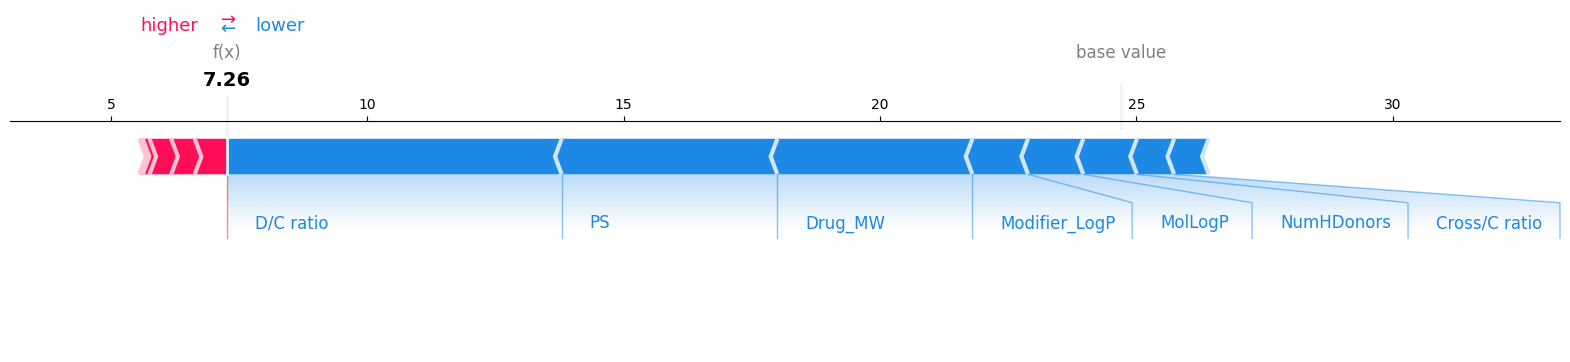

In [16]:
os.makedirs("ArticleFigures", exist_ok=True)

plt.figure(figsize=(18, 4))

shap.plots.force(
    explainer.expected_value,
    shap_values.values[36],
    feature_names=X.columns.tolist(),
    link="identity",
    plot_cmap="RdBu",
    matplotlib=True,
    show=False,
    ordering_keys=None,
    ordering_keys_time_format=None,
    text_rotation=0,
    contribution_threshold=0.05
)

fig = plt.gcf()

fig.savefig(
    "ArticleFigures/Figure_7B.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/Figure_7B.jpg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/Figure_7B.jpeg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/Figure_7B.tiff",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/Figure_7B.pdf",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

plt.show()
plt.close(fig)

In [17]:
MOD_Carboxymethyl_chitosan = df.loc[df['Modification'] == 'Chitosan']
MOD_Carboxymethyl_chitosan

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
0,1,Chitosan,Doxorubicin hydrochloride,TPP,0.07,0.33,1,3,0.0,0.0,0.0,367.86,0.89,580.00,8.01,489.30,12.40,6,0.42310
1,1,Chitosan,Doxorubicin hydrochloride,TPP,0.10,0.33,1,3,0.0,0.0,0.0,367.86,0.89,580.00,8.01,342.20,15.30,6,0.42310
2,1,Chitosan,Doxorubicin hydrochloride,TPP,0.17,0.33,1,3,0.0,0.0,0.0,367.86,0.89,580.00,8.01,209.60,14.90,6,0.42310
3,2,Chitosan,Vancomycin,Sodium carboxymethylcellulose,0.25,10.00,1,2,0.0,0.0,0.0,250000.00,4.50,1449.25,2.99,194.70,52.00,19,0.10620
4,2,Chitosan,Vancomycin,Sodium alginate,0.25,10.00,1,2,0.0,0.0,0.0,140000.00,3.60,1449.25,2.99,350.10,51.80,19,0.10620
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,19,Chitosan,oxaliplatin,TPP,0.27,0.25,1,2,0.0,0.0,0.0,367.86,0.89,397.29,1.36,188.40,12.40,2,1.55510
86,20,Chitosan,Levofloxacin,TPP,0.40,1.00,1,2,0.0,0.0,0.0,367.86,0.89,361.40,5.35,161.90,4.23,1,1.54400
87,20,Chitosan,Levofloxacin,TPP,0.40,0.67,1,2,0.0,0.0,0.0,367.86,0.89,361.40,5.35,176.97,4.02,1,1.54400
88,20,Chitosan,Levofloxacin,TPP,0.40,0.50,1,2,0.0,0.0,0.0,367.86,0.89,361.40,5.35,283.97,3.13,1,1.54400


In [18]:
MOD_Carboxymethyl_chitosan.loc[[44]]

,Formulation_number,Modification,Drug,Cross_linker,Cross/C ratio,D/C ratio,Chitosan_MW,Chitosan_DDA,DS,Modifier_LogP,Modifier_pka,Cross_MW,Cross_pka,Drug_MW,Drug_pka,PS,DL,NumHDonors,MolLogP
44,16,Chitosan,Rifampicin,TPP,0.04,0.25,1,3,0.0,0.0,0.0,367.86,0.89,822.9,6.8,199.5,23.05,6,4.33542


In [19]:
shap_values.values[44]

array([ 4.51440116e+00, -6.98456104e+00,  2.78506195e-01,  2.89681561e-01,
        7.94117064e-02, -1.64352858e-01, -7.31054750e-01,  8.31516023e-04,
        3.08141483e-01,  5.73592281e-01, -4.17211525e-01,  1.09086466e-01,
       -1.12650959e+00,  1.61331940e+00])

<Figure size 1800x400 with 0 Axes>

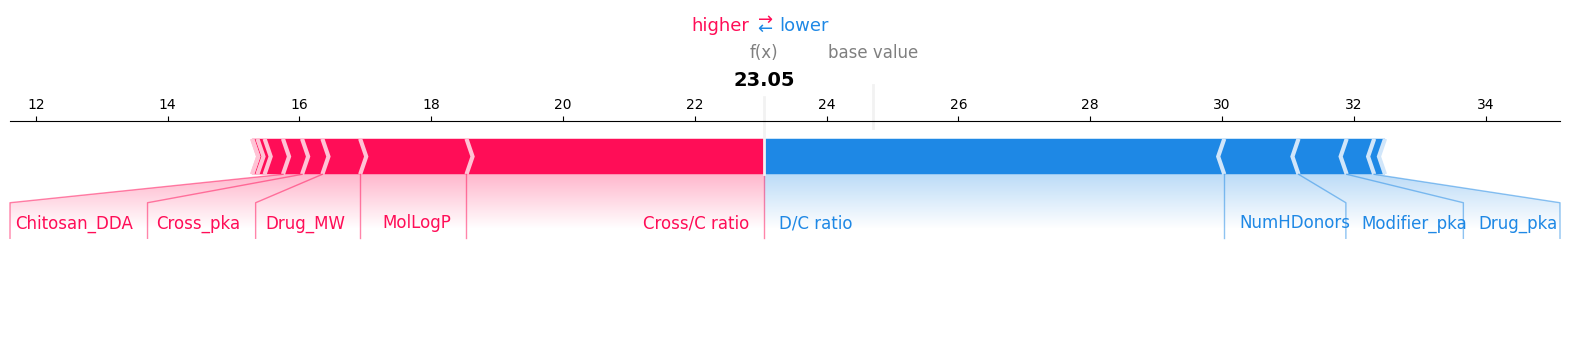

In [20]:
os.makedirs("ArticleFigures", exist_ok=True)

plt.figure(figsize=(18, 4))

shap.plots.force(
    explainer.expected_value,
    shap_values.values[44],
    feature_names=X.columns.tolist(),
    link="identity",
    plot_cmap="RdBu",
    matplotlib=True,
    show=False,
    ordering_keys=None,
    ordering_keys_time_format=None,
    text_rotation=0,
    contribution_threshold=0.05
)

fig = plt.gcf()

fig.savefig(
    "ArticleFigures/Figure_7C.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/Figure_7C.jpg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/Figure_7C.jpeg",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/Figure_7C.tiff",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

fig.savefig(
    "ArticleFigures/Figure_7C.pdf",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.2
)

plt.show()
plt.close(fig)